In [1]:
!pip install torchinfo -q
!pip install numpy
!pip install matplotlib
!pip install seaborn
!pip install pandas

import os
import sys

# Find environment (Colab or local)
IN_COLAB = 'google.colab' in sys.modules
print(f"Environment: {"Google Colab" if IN_COLAB else "Local"}")

if IN_COLAB:
    !pip install torch
else:
    !pip3 install torch torchvision --index-url https://download.pytorch.org/whl/cu126

Environment: Local
Looking in indexes: https://download.pytorch.org/whl/cu126


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split

import torchinfo

In [3]:
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("device:", device)

torch version: 2.14.1+cu126
device: cuda


In [4]:
# Load api token based on environment
if IN_COLAB:
    from google.colab import userdata
    os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')
else:
    !pip install python-dotenv
    from dotenv import load_dotenv
    load_dotenv()

# Change data dir path based on environment
if IN_COLAB:
    DATA_DIR = "/content/dataset"
else:
    DATA_DIR = "./dataset"

if not os.path.exists(DATA_DIR):
    !pip install -q kaggle
    !mkdir -p {DATA_DIR}
    !kaggle datasets download -d gpiosenka/sports-classification -p {DATA_DIR} --unzip

Dataset URL: https://www.kaggle.com/datasets/gpiosenka/sports-classification
License(s): CC0-1.0
100%|███████████████████████████████████████| 424M/424M [00:40<00:00, 10.9MB/s]



In [5]:
df = pd.read_csv(os.path.join(DATA_DIR, "sports.csv"))

In [6]:
df.head()

,class id,filepaths,labels,data set
0,0,train/air hockey/001.jpg,air hockey,train
1,0,train/air hockey/002.jpg,air hockey,train
2,0,train/air hockey/003.jpg,air hockey,train
3,0,train/air hockey/004.jpg,air hockey,train
4,0,train/air hockey/005.jpg,air hockey,train


In [7]:
print(df['data set'].value_counts())

data set
train    13493
test       500
valid      500
Name: count, dtype: int64


We're looking strictly at values in 'data set' coloumn. This means that we have ~13.5k images for training, 500 for testing and 500 for validation.

In [8]:
print("Number of unique sports:", df['labels'].nunique())

Number of unique sports: 100


In [9]:
class_distribution = pd.crosstab(df['labels'], df['data set'])

LINE_COUNT=5
print(f"Sample image layout for the first {LINE_COUNT} classes")
display(class_distribution.head(LINE_COUNT))

print("\nStatistics on the number of images per class across the individual splits")
print(class_distribution.describe())

Sample image layout for the first 5 classes


data set,test,train,valid
labels,,,
air hockey,5,112,5
ampute football,5,112,5
archery,5,132,5
arm wrestling,5,99,5
axe throwing,5,113,5



Statistics on the number of images per class across the individual splits
data set   test       train  valid
count     100.0  100.000000  100.0
mean        5.0  134.930000    5.0
std         0.0   21.497125    0.0
min         5.0   59.000000    5.0
25%         5.0  120.750000    5.0
50%         5.0  133.500000    5.0
75%         5.0  148.250000    5.0
max         5.0  191.000000    5.0


In [10]:
from PIL import Image

In [11]:
class SportsDataset(torch.utils.data.Dataset):
    def __init__(self, csv_file_path, root_dir, split='train', transform=None):
        df = pd.read_csv(csv_file_path)

        # We filter dataframe to keep only needed split ('train', 'valid', nebo 'test')
        self.df = df[df['data set'] == split].reset_index(drop=True)

        # We filter files that don't have image extensions
        valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
        self.df = self.df[self.df['filepaths'].str.lower().str.endswith(valid_extensions)].reset_index(drop=True)

        self.root_dir = root_dir
        self.transform = transform

        # We create a sorted list of unique classes and a dictionary for text-to-number conversion
        self.classes = sorted(self.df['labels'].unique())
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}

    def __len__(self):
        # Returns the line count of the filtered dataframe
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # Loads image from path
        img_path = os.path.join(self.root_dir, row['filepaths'])
        image = Image.open(img_path).convert("RGB")

        # Mapping of image to a numeric value
        label_str = row['labels']
        label = self.class_to_idx[label_str]

        # Aplication of transformation (if its provided)
        if self.transform:
            image = self.transform(image)

        return image, label

In [12]:
# We create instances of datasets (without transformations)
train_dataset = SportsDataset(csv_file_path='dataset/sports.csv', root_dir='dataset', split='train')
val_dataset = SportsDataset(csv_file_path='dataset/sports.csv', root_dir='dataset', split='valid')

print(f"Počet trénovacích obrázků: {len(train_dataset)}")
print(f"Počet validačních obrázků: {len(val_dataset)}")
print(f"Počet tříd: {len(train_dataset.classes)}")

# We load 1st sample
img, label = train_dataset[0]

print("\n--- Kontrola prvního vzorku ---")
print(f"Typ obrázku: {type(img)}")
print(f"Velikost obrázku: {img.size}")
print(f"Číselný label: {label}")
print(f"Slovní název sportu: {train_dataset.classes[label]}")

Počet trénovacích obrázků: 13492
Počet validačních obrázků: 500
Počet tříd: 100

--- Kontrola prvního vzorku ---
Typ obrázku: <class 'PIL.Image.Image'>
Velikost obrázku: (224, 224)
Číselný label: 0
Slovní název sportu: air hockey


In [ ]:
import torchvision.transforms as T
from torch.utils.data import DataLoader

# Detekce prostředí a OS
if 'google.colab' in sys.modules:
    NUM_WORKERS = 2 
elif os.name == 'nt':
    NUM_WORKERS = 0  # Windows
else:
    NUM_WORKERS = 2  # Linux / macOS

BATCH_SIZE = 64


# Definition of transformations
train_transform = T.Compose([
    T.Resize((224, 224)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Creation of datasets with applied transformations
train_dataset = SportsDataset(csv_file_path='dataset/sports.csv', root_dir='dataset', split='train', transform=train_transform)
val_dataset = SportsDataset(csv_file_path='dataset/sports.csv', root_dir='dataset', split='valid', transform=train_transform)

# Creation of Dataloaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

print(f"Počet batchů v train_loaderu: {len(train_loader)}")
print(f"Počet batchů ve val_loaderu: {len(val_loader)}")

Počet batchů v train_loaderu: 211
Počet batchů ve val_loaderu: 8


--- Kontrola tenzorů v batchi ---
Tvar tenzoru obrázků (B, C, H, W): torch.Size([64, 3, 224, 224])
Tvar tenzoru labelů (B,): torch.Size([64])


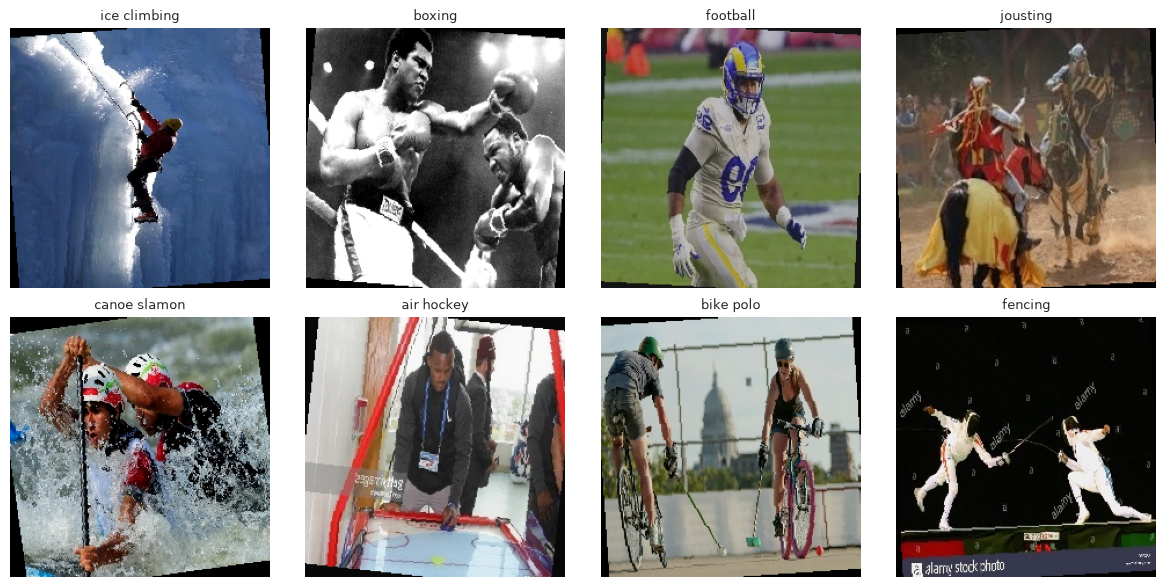

In [14]:
# We load 1 batch into DataLoader
images, labels = next(iter(train_loader))

print("--- Kontrola tenzorů v batchi ---")
print(f"Tvar tenzoru obrázků (B, C, H, W): {images.shape}")
print(f"Tvar tenzoru labelů (B,): {labels.shape}")

# Denormalization function (inverse function to T.normalize)
inv_normalize = T.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

# We plot first 8 images from batch
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    # Denormalization of image
    img_denorm = inv_normalize(images[i])

    # Conversion from PyTorch (C, H, W) to Matplotlib (H, W, C) and to NumPy array
    img_np = img_denorm.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np, 0, 1)

    ax.imshow(img_np)
    class_name = train_dataset.classes[labels[i].item()]
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# You need to make better model and tweak parameters (epochs, dropout, learning rate, activation functions, batches, etc.)
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=100, p_drop=0.2):
        super(BaselineCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()

        # Classification head with 256 features
        self.classifier = nn.Sequential(
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Dropout(p=p_drop),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.flatten(x)
        return self.classifier(x)

In [17]:
model = BaselineCNN(num_classes=len(train_dataset.classes)).to(device)
torchinfo.summary(model)

Layer (type:depth-idx)                   Param #
BaselineCNN                              --
├─Sequential: 1-1                        --
│    └─Conv2d: 2-1                       1,728
│    └─BatchNorm2d: 2-2                  128
│    └─ReLU: 2-3                         --
│    └─MaxPool2d: 2-4                    --
│    └─Conv2d: 2-5                       73,728
│    └─BatchNorm2d: 2-6                  256
│    └─ReLU: 2-7                         --
│    └─MaxPool2d: 2-8                    --
│    └─Conv2d: 2-9                       294,912
│    └─BatchNorm2d: 2-10                 512
│    └─ReLU: 2-11                        --
│    └─MaxPool2d: 2-12                   --
├─AdaptiveAvgPool2d: 1-2                 --
├─Flatten: 1-3                           --
├─Sequential: 1-4                        --
│    └─Linear: 2-13                      131,584
│    └─ReLU: 2-14                        --
│    └─Dropout: 2-15                     --
│    └─Linear: 2-16                      51,300
Tot

In [18]:
# Definition of loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)

        # zeros gradient
        optimizer.zero_grad()

        # 2nd Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass & Optimizer step (change of weights)
        loss.backward()
        optimizer.step()

        # Accumulation of metrics
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():  # We disable computations of gradients to save memory
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == labels.data).item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [19]:
baseline_model = BaselineCNN(num_classes=len(train_dataset.classes)).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)

num_epochs = 40

# Saving history for later plotting
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(baseline_model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(baseline_model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}] | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")

Epoch [1/40] | Train Loss: 3.8834 - Train Acc: 8.30% | Val Loss: 3.6125 - Val Acc: 11.60%
Epoch [2/40] | Train Loss: 3.4024 - Train Acc: 15.86% | Val Loss: 3.3005 - Val Acc: 14.20%
Epoch [3/40] | Train Loss: 3.1477 - Train Acc: 20.66% | Val Loss: 2.9751 - Val Acc: 25.40%
Epoch [4/40] | Train Loss: 2.9816 - Train Acc: 24.06% | Val Loss: 2.8580 - Val Acc: 22.60%
Epoch [5/40] | Train Loss: 2.8422 - Train Acc: 26.50% | Val Loss: 2.7457 - Val Acc: 27.60%
Epoch [6/40] | Train Loss: 2.7455 - Train Acc: 28.94% | Val Loss: 2.6994 - Val Acc: 28.60%
Epoch [7/40] | Train Loss: 2.6460 - Train Acc: 30.80% | Val Loss: 2.4810 - Val Acc: 33.80%
Epoch [8/40] | Train Loss: 2.5541 - Train Acc: 32.86% | Val Loss: 2.4431 - Val Acc: 37.60%
Epoch [9/40] | Train Loss: 2.4696 - Train Acc: 34.73% | Val Loss: 2.3840 - Val Acc: 34.00%
Epoch [10/40] | Train Loss: 2.3926 - Train Acc: 36.16% | Val Loss: 2.2960 - Val Acc: 37.20%
Epoch [11/40] | Train Loss: 2.3087 - Train Acc: 38.42% | Val Loss: 2.2520 - Val Acc: 40.00

KeyboardInterrupt: 

In [ ]:
epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

# Loss function graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Val Loss', marker='o')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Acc', marker='o')
plt.plot(epochs_range, history['val_acc'], label='Val Acc', marker='o')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
print("--- Spuštění Overfit Sanity Checku (16 vzorků) ---")

# 1st crop (16 samples)
sanity_dataset = torch.utils.data.Subset(train_dataset, range(16))
sanity_loader = DataLoader(sanity_dataset, batch_size=16, shuffle=False)

# Fresh model and new optimizer for test
sanity_model = BaselineCNN(num_classes=len(train_dataset.classes)).to(device)
sanity_optimizer = torch.optim.Adam(sanity_model.parameters(), lr=1e-3)

# Training
for epoch in range(100):
    loss, acc = train_epoch(sanity_model, sanity_loader, criterion, sanity_optimizer, device)

    if (epoch + 1) % 20 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1:3d}/100] - Loss: {loss:.4f} | Accuracy: {acc * 100:.2f}%")

if acc >= 0.99 and loss <= 0.05:
    print("\nSanity check prošel na 100 %! Gradietny protékají správně a pipeline nemá chyby.")
else:
    print("\nSanity check nesplnil očekávání. Zkontroluj učicí rychlost nebo architekturu.")